# **Libraries**

In [1]:
# ---------------- Standard Libraries ----------------
import os
import pickle
from pathlib import Path
from datetime import datetime
import time
# ---------------- Data Handling ----------------
import numpy as np
import pandas as pd

# ---------------- Visualization ----------------
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({
    'font.size': 9,
    'font.weight': 'bold',
    'font.family': 'serif'
})

# ---------------- Machine Learning (sklearn) ----------------
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix,
    roc_curve, auc, roc_auc_score, average_precision_score
)
# ---------------- Deep Learning (PyTorch) ----------------
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import TensorDataset, DataLoader
from torch.optim.lr_scheduler import _LRScheduler
from torchsummary import summary

# ---------------- CORAL (Ordinal Regression) ----------------
from coral_pytorch.losses import corn_loss
from coral_pytorch.dataset import corn_label_from_logits

# ---------------- File Handling ----------------
import h5py
import hdf5storage

# ---------------- Utilities ----------------
from tqdm import tqdm
import joblib
import shap

# ---------------- Custom Function ----------------
def load_pickle(filepath):
    """
    Load a Python object from a pickle file.

    Parameters
    ----------
    filepath : str
        Path to the .pkl file.

    Returns
    -------
    obj : any
        The Python object stored in the pickle file.
    """
    with open(filepath, 'rb') as f:
        obj = pickle.load(f)
    return obj

def extract_pid(filename):
    part = filename.split('_')[0]          
    pid_full = part.split('-')[1]          
    pid = pid_full[5:]                     
    return pid


# **Data load across all cohort: RASS, GCS, CAMS, ICANS**
**M22**
- Good neurological state (0): RASS (-1, 0), GCS (14, 15), CAMS (0, 1), ICANS (0, 1)
- Moderate state (1): RASS (-3, -2), GCS (8, 9, 10, 11, 12, 13), CAMS (2, 3), ICANS (2)
- Bad state (2): RASS (-5, -4), GCS (3, 4, 5, 6, 7), CAMS (4, 5, 6, 7), ICANS (3, 4)

In [2]:
def group_gcs(y):
    if 3 <= y <= 7: return 2
    elif 8 <= y <= 13: return 1
    elif 14 <= y <= 15: return 0
    return None

def group_rass(y):
    if -5 <= y <= -4: return 2
    elif -3 <= y <= -2: return 1
    elif -1 <= y <= 0: return 0
    return None

def group_icans(y):
    if 0 <= y <= 1: return 0
    elif y == 2: return 1
    elif 3 <= y <= 4: return 2
    return None

def group_cams(x):
    if 0 <= x <= 1: return 0
    elif 2 <= x <= 3: return 1
    elif 4 <= x <= 7: return 2
    return None

In [3]:

NESI_ROOT = Path('/home/ayush/Desktop/GitHub-YAMA/NESI')
# ------------------- CAMS - Dataset --------------------------
metadata_path_CAMS = NESI_ROOT / "model" / "Training" / "CAMSTraining_Final_Metadata.csv"
df_CAMS_metadata = pd.read_csv(metadata_path_CAMS)
df_CAMS_metadata["GroupedScore"] = df_CAMS_metadata["CAMS_SF"].apply(group_cams)
df_CAMS_metadata = df_CAMS_metadata.rename(columns={'CAMS_SF': 'RawScore'})
df_CAMS_metadata['Dataset'] = 'CAMS'
df_CAMS_metadata['TransformedScore'] = df_CAMS_metadata['RawScore']
df_CAMS_metadata = df_CAMS_metadata[['BDSPPatientID', 'Dataset', 'MorgothOutputFilename', 'RawScore', 'GroupedScore', 'TransformedScore']]

# ------------------- ICANS - Dataset --------------------------
metadata_path_ICANS = NESI_ROOT / "model" / "Training" / "ICANSTraining_Final_Metadata.csv"
df_ICANS_metadata = pd.read_csv(metadata_path_ICANS)
df_ICANS_metadata["GroupedScore"] = df_ICANS_metadata["ICANS_raw"].apply(group_icans)
df_ICANS_metadata = df_ICANS_metadata.rename(columns={'StudyID':'BDSPPatientID',                                                      
                                                      'ICANS_raw': 'RawScore'})
df_ICANS_metadata['Dataset'] = 'ICANS'
df_ICANS_metadata['TransformedScore'] = df_ICANS_metadata['RawScore']
df_ICANS_metadata = df_ICANS_metadata[['BDSPPatientID', 'Dataset', 'MorgothOutputFilename', 'RawScore', 'GroupedScore', 'TransformedScore']]

# ------------------- GCS - Dataset --------------------------
metadata_path_GCS = NESI_ROOT / "model" / "Training" / "GCSTraining_Final_Metadata.csv"
df_GCS_metadata = pd.read_csv(metadata_path_GCS)
df_GCS_metadata['Filename'] = df_GCS_metadata['Filename'].astype(str) + '.csv'
df_GCS_metadata['GroupedScore'] = df_GCS_metadata['GCS_value'].apply(group_gcs)
df_GCS_metadata['BDSPPatientID'] = df_GCS_metadata['Filename'].apply(extract_pid)
df_GCS_metadata = df_GCS_metadata.rename(columns={'Filename': 'MorgothOutputFilename',
                                                  'GCS_value': 'RawScore'})
df_GCS_metadata['Dataset'] = 'GCS'
df_GCS_metadata['TransformedScore'] = 15-df_GCS_metadata['RawScore']
df_GCS_metadata = df_GCS_metadata[['BDSPPatientID', 'Dataset', 'MorgothOutputFilename', 'RawScore', 'GroupedScore', 'TransformedScore']]

# ------------------- RASS - Dataset --------------------------
metadata_path_RASS = NESI_ROOT / "model" / "Training" / "RASSTraining_Final_Metadata.csv"
df_RASS_metadata=pd.read_csv(metadata_path_RASS)
df_RASS_metadata['Filename'] = df_RASS_metadata['Filename'].str.rstrip("'") + '.csv'
df_RASS_metadata = df_RASS_metadata[
    ~df_RASS_metadata['RASS_value'].isin([1, 2, 3, 4])
]
df_RASS_metadata['GroupedScore'] = df_RASS_metadata['RASS_value'].apply(group_rass)
df_RASS_metadata['BDSPPatientID'] = df_RASS_metadata['Filename'].apply(extract_pid)
df_RASS_metadata['Dataset'] = 'RASS'
df_RASS_metadata = df_RASS_metadata.rename(columns={'Filename': 'MorgothOutputFilename',
                                                    'RASS_value': 'RawScore'})
df_RASS_metadata['TransformedScore'] = -df_RASS_metadata['RawScore']
df_RASS_metadata = df_RASS_metadata[['BDSPPatientID', 'Dataset', 'MorgothOutputFilename', 'RawScore', 'GroupedScore', 'TransformedScore']]

## ------------------ FULL DATASET (RASS- GCS - CAMS - ICANS) -------------------------
df_all_metadata = pd.concat(
    [df_RASS_metadata, df_GCS_metadata, df_CAMS_metadata, df_ICANS_metadata], # ],
    axis=0,
    ignore_index=True
)

df_all_metadata

,BDSPPatientID,Dataset,MorgothOutputFilename,RawScore,GroupedScore,TransformedScore
0,111189188,RASS,sub-S0001111189188_ses-12_eeg_10min_seg1.csv,-4,2,4
1,111189188,RASS,sub-S0001111189188_ses-12_eeg_10min_seg2.csv,-4,2,4
2,111189188,RASS,sub-S0001111189188_ses-12_eeg_10min_seg3.csv,-4,2,4
3,111189188,RASS,sub-S0001111189188_ses-12_eeg_10min_seg5.csv,-4,2,4
4,111189188,RASS,sub-S0001111189188_ses-2_eeg_10min_seg1.csv,-5,2,5
...,...,...,...,...,...,...
209761,1670,ICANS,1670_seg4_SourceStart_2019-10-20 09:06:30.csv,0,0,0
209762,1215,ICANS,1215_seg5_SourceStart_2020-01-23 12:05:37.csv,0,0,0
209763,1962,ICANS,1962_seg1_SourceStart_2019-05-02 16:41:32.csv,0,0,0
209764,1916,ICANS,1916_seg0_SourceStart_2019-05-05 14:34:40.csv,0,0,0


## **Some sanity chcek on individual datasets: Common subject IDs and Common FileNames if any**

In [4]:
sets = {
    'RASS': set(df_RASS_metadata['BDSPPatientID']),
    'GCS': set(df_GCS_metadata['BDSPPatientID']),
    'CAMS': set(df_CAMS_metadata['BDSPPatientID']),
    'ICANS': set(df_ICANS_metadata['BDSPPatientID'])
}

import itertools

pairwise_overlap = {}
for (name1, set1), (name2, set2) in itertools.combinations(sets.items(), 2):
    pairwise_overlap[f"{name1} & {name2}"] = len(set1.intersection(set2))

print("PAIRWISE SUBJECT OVERLAP")
print("=" * 40)

for k, v in pairwise_overlap.items():
    print(f"{k}: {v}")

print("=" * 40)

print('Total subjects in full dataset (RASS+GCS+CAMS+ICANS) ==> '+str(df_all_metadata['BDSPPatientID'].nunique()))
print('\n')
rass_ids = set(df_RASS_metadata['BDSPPatientID'])
gcs_ids = set(df_GCS_metadata['BDSPPatientID'])

common_ids = rass_ids.intersection(gcs_ids)
only_rass = rass_ids - gcs_ids
only_gcs = gcs_ids - rass_ids

df_rass_common = df_RASS_metadata[df_RASS_metadata['BDSPPatientID'].isin(common_ids)]
df_gcs_common = df_GCS_metadata[df_GCS_metadata['BDSPPatientID'].isin(common_ids)]

rass_files = set(df_rass_common['MorgothOutputFilename'])
gcs_files = set(df_gcs_common['MorgothOutputFilename'])

common_files = rass_files.intersection(gcs_files)

print("Unique RASS subjects in RASS cohort:", len(rass_ids))
print("Unique GCS subjects in GCS cohort:", len(gcs_ids)); 

print("Common subjects in RASS and GCS dataset:", len(common_ids)); 
print("Only RASS unique subjects (in RASS cohort):", len(only_rass))
print("Only GCS unique subjects (in GCS cohort):", len(only_gcs)); print('\n')

print("RASS files (common subjects):", len(rass_files))
print("GCS files (common subjects):", len(gcs_files))
print("Common files between datasets:", len(common_files))

PAIRWISE SUBJECT OVERLAP
RASS & GCS: 5512
RASS & CAMS: 0
RASS & ICANS: 0
GCS & CAMS: 0
GCS & ICANS: 0
CAMS & ICANS: 0
Total subjects in full dataset (RASS+GCS+CAMS+ICANS) ==> 8551


Unique RASS subjects in RASS cohort: 6191
Unique GCS subjects in GCS cohort: 7112
Common subjects in RASS and GCS dataset: 5512
Only RASS unique subjects (in RASS cohort): 679
Only GCS unique subjects (in GCS cohort): 1600


RASS files (common subjects): 89290
GCS files (common subjects): 100454
Common files between datasets: 50062


# **Split the dataset:**
 - Subject independent and startified by dataset groups (RASS, GCS, CAMS, ICANS)**

In [5]:
df_subjects = df_all_metadata[['BDSPPatientID', 'Dataset']].drop_duplicates()

from sklearn.model_selection import train_test_split

train_val, test = train_test_split(
    df_subjects,
    test_size=0.2,
    stratify=df_subjects['Dataset'],
    random_state=42
)

train, val = train_test_split(
    train_val,
    test_size=0.125,
    stratify=train_val['Dataset'],
    random_state=42
)

train_ids = set(train['BDSPPatientID'])
val_ids = set(val['BDSPPatientID'])
test_ids = set(test['BDSPPatientID'])

def assign_split(pid):
    if pid in train_ids:
        return 'Train'
    elif pid in val_ids:
        return 'Val'
    elif pid in test_ids:
        return 'Test'
    else:
        return 'None'

df_all_metadata['Split'] = df_all_metadata['BDSPPatientID'].apply(assign_split)

df_train = df_all_metadata[df_all_metadata['Split'] == 'Train'].reset_index(drop=True)
df_val   = df_all_metadata[df_all_metadata['Split'] == 'Val'].reset_index(drop=True)
df_test  = df_all_metadata[df_all_metadata['Split'] == 'Test'].reset_index(drop=True)

print("Train shape:", df_train.shape)
print("Val shape:", df_val.shape)
print("Test shape:", df_test.shape)

# ------------ Deatils of each Train/Val/Test files: Data distribution accross ecah class --------
# def print_split_histograms(df_train, df_val, df_test):
#     splits = {
#         "Train": df_train,
#         "Val": df_val,
#         "Test": df_test
#     }
#     for split_name, df in splits.items():

#         print("\n" + "="*50)
#         print(split_name)

#         table = pd.crosstab(df['Dataset'], df['GroupedScore'])

#         print(table)
#         print("\nRow totals (No of 10-min EEGs per Dataset):")
#         print(table.sum(axis=1))

# print_split_histograms(df_train, df_val, df_test)

Train shape: (186930, 7)
Val shape: (12731, 7)
Test shape: (10105, 7)


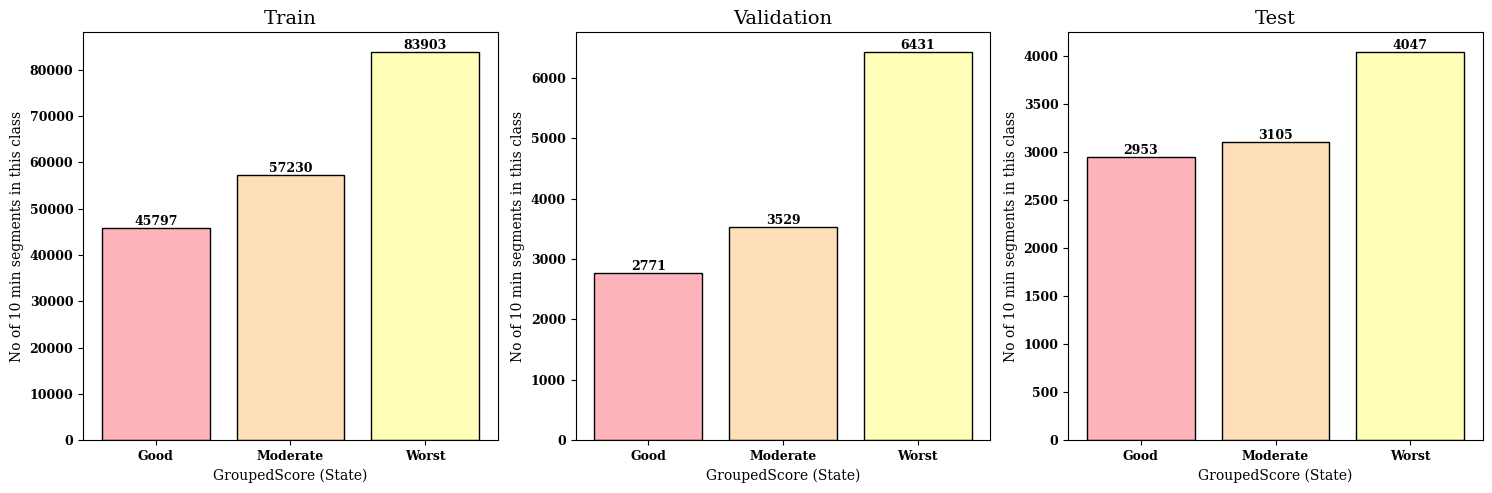

In [6]:
import matplotlib.pyplot as plt

# Define pastel colors and the label mapping
pastel_colors = ['#ffb3ba', '#ffdfba', '#ffffba'] # Pink, Orange, Yellow pastels
label_map = {'0': 'Good', '1': 'Moderate', '2': 'Worst'}

fig, axs = plt.subplots(1, 3, figsize=(15, 5))

dfs = [df_train, df_val, df_test]
titles = ["Train", "Validation", "Test"]

for i, (df, title) in enumerate(zip(dfs, titles)):
    # Get counts and ensure index is string for categorical plotting
    counts = df['GroupedScore'].value_counts().sort_index()
    x_labels = [label_map.get(str(idx), str(idx)) for idx in counts.index]
    
    # Plot bars with black edges and pastel colors
    bars = axs[i].bar(x_labels, counts.values, 
                      color=pastel_colors[:len(counts)], 
                      edgecolor='black')
    
    # Add numbers above the bars
    for bar in bars:
        height = bar.get_height()
        axs[i].text(bar.get_x() + bar.get_width()/2., height + 0.1,
                    f'{int(height)}', ha='center', va='bottom', fontweight='bold')

    # Formatting
    axs[i].set_title(title, fontsize=14)
    axs[i].set_xlabel("GroupedScore (State)", fontsize=10)
    axs[i].set_ylabel("No of 10 min segments in this class", fontsize=10)

plt.tight_layout()
plt.show()

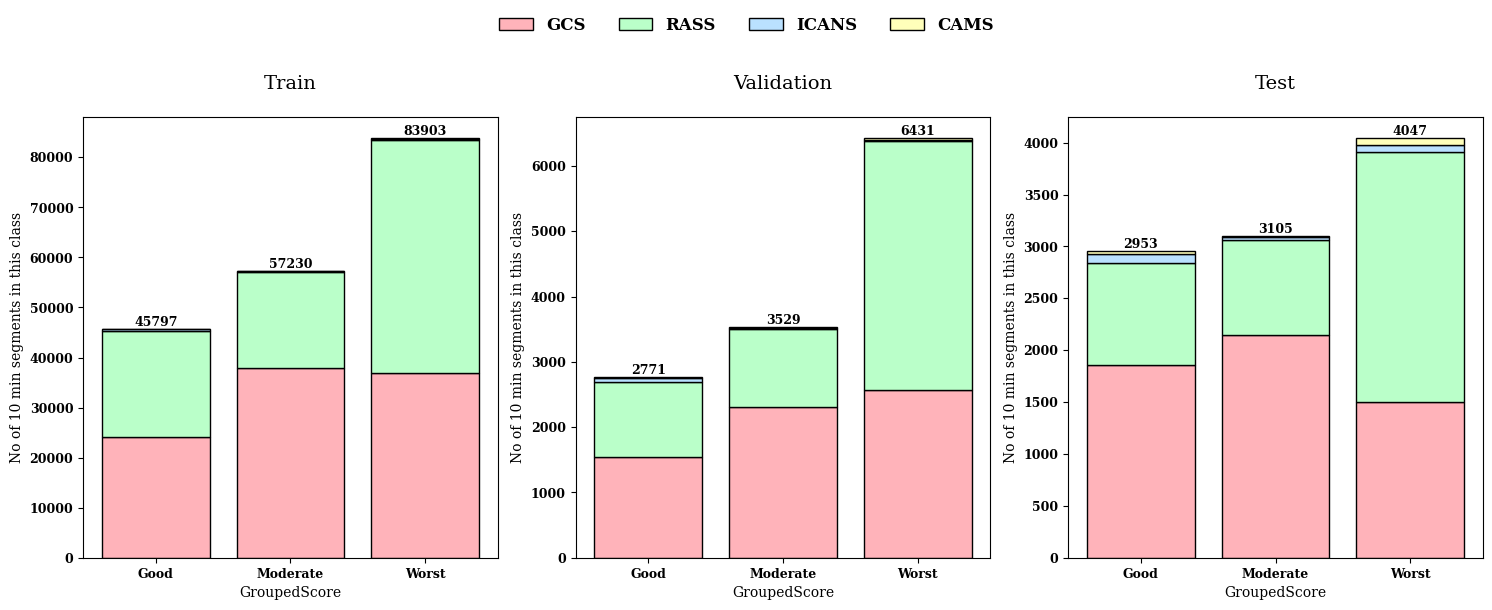

In [7]:
import matplotlib.pyplot as plt
import pandas as pd

# Define colors and dataset order
dataset_order = ['GCS', 'RASS', 'ICANS', 'CAMS'] 
# Using a pastel palette
pastel_colors = ['#ffb3ba', '#baffc9', '#bae1ff', '#ffffba'] 
label_map = {0: 'Good', 1: 'Moderate', 2: 'Worst'}

fig, axs = plt.subplots(1, 3, figsize=(15, 6))

dfs = [df_train, df_val, df_test]
titles = ["Train", "Validation", "Test"]

for i, (df, title) in enumerate(zip(dfs, titles)):
    # Prepare data: Group by Score and Dataset, then pivot
    plot_data = df.groupby(['GroupedScore', 'Dataset']).size().unstack(fill_value=0)
    
    # Ensure all classes (0,1,2) and datasets are present for consistent plotting
    plot_data = plot_data.reindex(index=[0, 1, 2], columns=dataset_order, fill_value=0)
    
    x_labels = [label_map[idx] for idx in plot_data.index]
    bottom = pd.Series([0, 0, 0], index=plot_data.index)

    # Plot each dataset layer
    for j, dataset in enumerate(dataset_order):
        counts = plot_data[dataset]
        bars = axs[i].bar(x_labels, counts, bottom=bottom, 
                          color=pastel_colors[j], edgecolor='black', label=dataset)
        bottom += counts

    # Add total count numbers above the stacked bars
    for idx, total_height in enumerate(bottom):
        axs[i].text(idx, total_height + 0.1, f'{int(total_height)}', 
                    ha='center', va='bottom', fontweight='bold')

    # Formatting
    axs[i].set_title(title, fontsize=14, pad=20)
    axs[i].set_xlabel("GroupedScore", fontsize=10)
    axs[i].set_ylabel("No of 10 min segments in this class", fontsize=10)

# Create legend above the 2nd subfigure head
# We use the handles from one of the axes
handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.05),
           ncol=4, frameon=False, fontsize=12)

plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to make room for the top legend
plt.show()

# **Feature Engineering**

In [8]:
import os
import numpy as np
import pandas as pd
from tqdm import tqdm


def morgoth_output_file_location(data_group):
    base_paths = {
        "RASS": "/home/ayush/Desktop/MGB_RASS_EEGs/RASS_ALL_EEG_10min/MORGOTH_embeddings",
        "GCS": "/home/ayush/Desktop/MGB_GCS_EEGs/MORGOTH_GCS_Embeddings",
        "CAMS": "/home/ayush/Desktop/CAM-S_dataset/MORGOTH_Embeddings",
        "ICANS": "/home/ayush/Desktop/ICANS_dataset/Morgoth_embeddings_for_model"
    }

    root = base_paths[data_group]

    return {
        "SLOWING": os.path.join(root, "SLOWING"),
        "FOCGEN": os.path.join(root, "FOCGEN"),
        "IIIC": os.path.join(root, "IIIC"),
        "NM": os.path.join(root, "NM"),
        "BS": os.path.join(root, "BS"),
        "SLEEP": os.path.join(root, "SLEEP")
    }


def load_feature(path, filename):
    df = pd.read_csv(os.path.join(path, filename))
    if "pred_class" in df.columns:
        df = df.drop(columns=["pred_class"])
    return df.values


def morgoth_10minfea_matrix(data_frame):
    features = []
    file_names = []

    for row in tqdm(data_frame.itertuples(index=False), total=len(data_frame)):
        fname = row.MorgothOutputFilename
        dataset = row.Dataset

        paths = morgoth_output_file_location(dataset)

        sleep = load_feature(paths["SLEEP"], fname)
        nm = load_feature(paths["NM"], fname)
        bs = load_feature(paths["BS"], fname)

        focgen = load_feature(paths["FOCGEN"], fname)
        slowing = load_feature(paths["SLOWING"], fname)
        iiic = load_feature(paths["IIIC"], fname)

        subject_feature = np.concatenate(
            [sleep, nm, bs, focgen, slowing, iiic],
            axis=1
        )

        features.append(subject_feature)
        file_names.append(fname)

    X = np.stack(features, axis=0)

    Y_grouped = data_frame["GroupedScore"].to_numpy()
    Y_raw = data_frame["RawScore"].to_numpy()
    dataset_names = data_frame["Dataset"].to_numpy()
    file_names = np.array(file_names)

    print("Grouped Label shape:", Y_grouped.shape)
    print("Raw Label shape:", Y_raw.shape)
    print("Feature matrix shape:", X.shape)
    
    return X, Y_grouped, Y_raw, dataset_names, file_names

In [9]:
X_train_data, Ygrouped_train, Yraw_train, train_dataset_names,trn_filenames = morgoth_10minfea_matrix(df_train)
X_val_data, Ygrouped_val, Yraw_val, val_dataset_names, val_filenames = morgoth_10minfea_matrix(df_val)
X_tst_data, Ygrouped_tst, Yraw_tst, tst_dataset_names, tst_filenames = morgoth_10minfea_matrix(df_test)

100%|██████████████████████████████████| 186930/186930 [23:27<00:00, 132.83it/s]


Grouped Label shape: (186930,)
Raw Label shape: (186930,)
Feature matrix shape: (186930, 591, 17)


100%|████████████████████████████████████| 12731/12731 [01:33<00:00, 136.34it/s]


Grouped Label shape: (12731,)
Raw Label shape: (12731,)
Feature matrix shape: (12731, 591, 17)


100%|████████████████████████████████████| 10105/10105 [01:09<00:00, 146.34it/s]


Grouped Label shape: (10105,)
Raw Label shape: (10105,)
Feature matrix shape: (10105, 591, 17)


# **Triplet Set Creation**

In [10]:
import torch
from torch.utils.data import Dataset
import numpy as np

class TripletDataset(Dataset):
    def __init__(self, X, y_grouped, y_raw, y_dataset):
        self.X = X
        self.y_grouped = y_grouped
        self.y_raw = y_raw
        self.y_dataset = np.array(y_dataset)

        self.unique_datasets = np.unique(self.y_dataset)

        # dataset → indices
        self.dataset_indices = {
            d: np.where(self.y_dataset == d)[0]
            for d in self.unique_datasets
        }

        # label → indices (FIXED)
        self.label_indices = {
            int(l.item()): torch.where(self.y_grouped == l)[0]
            for l in torch.unique(self.y_grouped)
        }

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):

        # -------------------------
        # 1. BALANCED ANCHOR SAMPLING
        # -------------------------
        anchor_dataset = np.random.choice(self.unique_datasets)
        anchor_pool = self.dataset_indices[anchor_dataset]
        anchor_idx = np.random.choice(anchor_pool)

        anchor_x = self.X[anchor_idx]
        anchor_g = self.y_grouped[anchor_idx]
        anchor_r = self.y_raw[anchor_idx]
        anchor_d = self.y_dataset[anchor_idx]

        # -------------------------
        # 2. POSITIVE (same label)
        # -------------------------
        pos_pool = self.label_indices[int(anchor_g.item())]

        # avoid picking same index (optional but better)
        if len(pos_pool) > 1:
            pos_pool = pos_pool[pos_pool != anchor_idx]

        pos_idx = pos_pool[torch.randint(len(pos_pool), (1,)).item()]

        pos_x = self.X[pos_idx]
        pos_g = self.y_grouped[pos_idx]
        pos_r = self.y_raw[pos_idx]
        pos_d = self.y_dataset[pos_idx]

        # -------------------------
        # 3. NEGATIVE (different label)
        # -------------------------
        all_labels = list(self.label_indices.keys())
        neg_labels = [l for l in all_labels if l != int(anchor_g.item())]

        neg_label = np.random.choice(neg_labels)
        neg_pool = self.label_indices[neg_label]

        neg_idx = neg_pool[torch.randint(len(neg_pool), (1,)).item()]

        neg_x = self.X[neg_idx]
        neg_g = self.y_grouped[neg_idx]
        neg_r = self.y_raw[neg_idx]
        neg_d = self.y_dataset[neg_idx]

        return (
            anchor_x, pos_x, neg_x,
            anchor_g, pos_g, neg_g,
            anchor_r, pos_r, neg_r,
            anchor_d, pos_d, neg_d
        )

## **Dataloader**

In [11]:
X_train_data_trch = torch.tensor(X_train_data, dtype=torch.float32)
X_val_data_trch   = torch.tensor(X_val_data, dtype=torch.float32)
X_tst_data_trch   = torch.tensor(X_tst_data, dtype=torch.float32)

Ygrouped_train_trch = torch.tensor(Ygrouped_train, dtype=torch.long)
Ygrouped_val_trch   = torch.tensor(Ygrouped_val, dtype=torch.long)
Ygrouped_tst_trch   = torch.tensor(Ygrouped_tst, dtype=torch.long)

Yraw_train_trch = torch.tensor(Yraw_train, dtype=torch.long)
Yraw_val_trch   = torch.tensor(Yraw_val, dtype=torch.long)
Yraw_tst_trch   = torch.tensor(Yraw_tst, dtype=torch.long)

train_dataset_names = np.array(train_dataset_names)
val_dataset_names   = np.array(val_dataset_names)
tst_dataset_names   = np.array(tst_dataset_names)

tst_dataset = TripletDataset(
    X_tst_data_trch,
    Ygrouped_tst_trch,
    Yraw_tst_trch,
    tst_dataset_names
)

train_dataset = TripletDataset(
    X_train_data_trch,
    Ygrouped_train_trch,
    Yraw_train_trch,
    train_dataset_names
)

val_dataset = TripletDataset(
    X_val_data_trch,
    Ygrouped_val_trch,
    Yraw_val_trch,
    val_dataset_names
)

print(f"Size of trainset : {len(train_dataset)}")
print(f"Size of validset : {len(val_dataset)}")
print(f"Size of Testset : {len(tst_dataset)}")

bs = 64
train_dataloader = DataLoader(train_dataset, batch_size=bs, shuffle=True)
val_dataloader   = DataLoader(val_dataset, batch_size=bs, shuffle=False)
tst_dataloader   = DataLoader(tst_dataset, batch_size=bs, shuffle=False)

Size of trainset : 186930
Size of validset : 12731
Size of Testset : 10105


## **Triplet set visualization**

In [12]:
import matplotlib.pyplot as plt
import numpy as np

def plot_triplet(
    anchor_x, pos_x, neg_x,
    anchor_g, pos_g, neg_g,
    anchor_r, pos_r, neg_r,
    anchor_d, pos_d, neg_d
):

    def prep(x):
        return x.detach().cpu().numpy() if hasattr(x, "detach") else np.array(x)

    anchor_x = prep(anchor_x)
    pos_x = prep(pos_x)
    neg_x = prep(neg_x)

    fig, axs = plt.subplots(1, 3, figsize=(18, 6))

    triplets = [
        (anchor_x, "Anchor", anchor_g, anchor_d, anchor_r, axs[0]),
        (pos_x, "Positive", pos_g, pos_d, pos_r, axs[1]),
        (neg_x, "Negative", neg_g, neg_d, neg_r, axs[2]),
    ]

    for x, role, g, d, r, ax in triplets:

        im = ax.imshow(x, aspect='auto', cmap='Blues')
        label_map = {
            0: "Good Neuro state",
            1: "Moderate Neuro state",
            2: "Bad Neuro state"
        }

        ax.set_title(
            f"{role}: Group {g} ({label_map.get(int(g), 'Unknown')})\nDataset: {d}, Raw: {r}",
            fontsize=10
        )

        ax.set_xlabel("Feature dimension")
        ax.set_ylabel("Time / segments")

        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.show()

# **Model development (classe defenitions)**

In [13]:
#-------------------------- ResNet-GAP only model -------------------------------------
import torch.nn.functional as F
class ResidualBlock1D(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()

        self.conv1 = nn.Conv1d(in_ch, out_ch, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm1d(out_ch)

        self.conv2 = nn.Conv1d(out_ch, out_ch, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm1d(out_ch)

        # If channels differ → use 1x1 conv for skip
        self.shortcut = nn.Sequential()
        if in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv1d(in_ch, out_ch, kernel_size=1),
                nn.BatchNorm1d(out_ch)
            )

    def forward(self, x):
        identity = self.shortcut(x)

        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        out = out + identity
        return F.relu(out)

class MORGOTH_ResNet1D_onlyGAP_CORAL(nn.Module):
    def __init__(self, num_features, filters=None, use_logit=True):
        super().__init__()
        self.use_logit = use_logit
        

        if filters is None:
            filters = [64, 128, 128, 256, 256]

        # Initial conv
        self.conv0 = nn.Conv1d(num_features, filters[0], kernel_size=7, padding=3)
        self.bn0 = nn.BatchNorm1d(filters[0])
        self.pool0 = nn.MaxPool1d(kernel_size=2)

        # ResNet blocks
        blocks = []
        in_ch = filters[0]
        for out_ch in filters:
            blocks.append(ResidualBlock1D(in_ch, out_ch))
            blocks.append(nn.MaxPool1d(kernel_size=2))
            in_ch = out_ch
        self.resnet_layers = nn.Sequential(*blocks)

        # GAP but DON'T squeeze yet
        self.gap = nn.AdaptiveAvgPool1d(1)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(256, 40)
    def forward(self, x):
        if self.use_logit:
            eps = 1e-6
            x = torch.log((x + eps) / (1 - x + eps))

        x = x.permute(0, 2, 1)

        x = self.pool0(F.relu(self.bn0(self.conv0(x))))
        x = self.resnet_layers(x)

        # GAP: (B,C,1)
        x = self.gap(x).squeeze(-1)
        x = self.dropout(x)
        x = F.relu(x)
        x = self.fc(x)
        x = F.normalize(x, p=2, dim=1)
        return x

# **Contrastive Training Loop**

In [14]:
import os
import torch
import copy
import numpy as np

def Training_triplet_function(
    model,
    lr,
    n_epochs,
    train_dl,
    valid_dl,
    save_loc,
    model_prefix,
    margin,
    device="cuda",
    patience = 10
):

    best_val_loss = float("inf")
    epochs_no_improve = 0
    
    model = model.to(device)
    
    os.makedirs(save_loc, exist_ok=True)

    opt = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = torch.nn.TripletMarginLoss(margin=margin, p=2)

    best_model_wts = copy.deepcopy(model.state_dict())

    trainloss_history = []
    valloss_history = []

    print("Start Triplet Model Training")

    for epoch in range(1, n_epochs + 1):

        # ---------------- TRAIN ----------------
        model.train()
        running_loss = 0.0

        for batch in train_dl:

            (
                anchor_x, pos_x, neg_x,
                _, _, _,
                _, _, _,
                _, _, _
            ) = batch

            anchor_x = anchor_x.to(device)
            pos_x = pos_x.to(device)
            neg_x = neg_x.to(device)

            opt.zero_grad()

            anchor_emb = model(anchor_x)
            pos_emb = model(pos_x)
            neg_emb = model(neg_x)

            loss = criterion(anchor_emb, pos_emb, neg_emb)

            loss.backward()
            opt.step()

            running_loss += loss.item()

        train_loss = running_loss / len(train_dl)
        trainloss_history.append(train_loss)

        # ---------------- VALIDATION ----------------
        model.eval()
        running_val_loss = 0.0

        with torch.no_grad():
            for batch in valid_dl:

                (
                    anchor_x, pos_x, neg_x,
                    _, _, _,
                    _, _, _,
                    _, _, _
                ) = batch

                anchor_x = anchor_x.to(device)
                pos_x = pos_x.to(device)
                neg_x = neg_x.to(device)

                anchor_emb = model(anchor_x)
                pos_emb = model(pos_x)
                neg_emb = model(neg_x)

                val_loss = criterion(anchor_emb, pos_emb, neg_emb)

                running_val_loss += val_loss.item()

        val_loss = running_val_loss / len(valid_dl)
        valloss_history.append(val_loss)

        print(f"Epoch {epoch:3d} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

        # ---------------- EARLY STOPPING ----------------
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            epochs_no_improve = 0

            best_model_wts = copy.deepcopy(model.state_dict())

            best_path = os.path.join(save_loc, f"{model_prefix}_BestModel.pth")

            if os.path.exists(best_path):
                os.remove(best_path)

            torch.save(best_model_wts, best_path)

            print(f"Saved best model at epoch {epoch}")

        else:
            epochs_no_improve += 1

            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch}")
                break

    final_path = os.path.join(save_loc, f"{model_prefix}_valLoss_{best_val_loss:.6f}.pth")

    torch.save(best_model_wts, final_path)

    print(f"Best Val Loss: {best_val_loss:.4f}")
    print(f"Model saved at: {final_path}")

    return trainloss_history, valloss_history, final_path

# **Train model**

In [15]:
tic = time.perf_counter()
model_onlygap = MORGOTH_ResNet1D_onlyGAP_CORAL(num_features=17)

base_model_dir = '/home/ayush/Desktop/NESI_review_material/24ModelBaseline/ModelCheckpoints/TripletModels'
trainloss_history, valloss_history, final_path = Training_triplet_function(
    model= model_onlygap,
    lr=0.005,
    n_epochs=200,
    train_dl= train_dataloader,
    valid_dl= val_dataloader,
    save_loc=base_model_dir,
    model_prefix='Triplet_M22',
    margin=0.2,
    device="cuda:1",
    patience = 10
)
toc = time.perf_counter()
print('='*40)
print(f"Elapsed time: {(toc - tic)/60:0.4f} mins")

Start Triplet Model Training


KeyboardInterrupt: 

# **Embedding Extrcation process and visulaize them**

## **Get embeddings**

In [16]:
device = "cuda:1" if torch.cuda.is_available() else "cpu"

# --------- LOAD MODEL ----------
model_trained = MORGOTH_ResNet1D_onlyGAP_CORAL(num_features=17)
model_trained.load_state_dict(
    torch.load("/home/ayush/Desktop/NESI_review_material/24ModelBaseline/ModelCheckpoints/TripletModels/Triplet_M22_BestModel.pth",
               map_location=device,
               weights_only=True)
)
model_trained = model_trained.to(device)
model_trained.eval()

# --------- CREATE LOADERS ----------
train_ds_all = TensorDataset(X_train_data_trch)
val_ds_all   = TensorDataset(X_val_data_trch)
tst_ds_all   = TensorDataset(X_tst_data_trch)

train_dl_all = DataLoader(train_ds_all, batch_size=128, shuffle=False)
val_dl_all   = DataLoader(val_ds_all, batch_size=128, shuffle=False)
tst_dl_all   = DataLoader(tst_ds_all, batch_size=128, shuffle=False)

# --------- FUNCTION TO EXTRACT EMBEDDINGS ----------
def get_embeddings(model_trained, dataloader):
    all_embeddings = []

    with torch.no_grad():
        for (x,) in dataloader:
            x = x.to(device)
            emb = model_trained(x)
            all_embeddings.append(emb.cpu())

    return torch.cat(all_embeddings, dim=0)

# --------- GET EMBEDDINGS ----------
train_embeddings = get_embeddings(model_trained, train_dl_all)
val_embeddings   = get_embeddings(model_trained, val_dl_all)
tst_embeddings   = get_embeddings(model_trained, tst_dl_all)

print("Train embeddings shape:", train_embeddings.shape)
print("Val embeddings shape:", val_embeddings.shape)
print("Test embeddings shape:", tst_embeddings.shape)

Train embeddings shape: torch.Size([186930, 40])
Val embeddings shape: torch.Size([12731, 40])
Test embeddings shape: torch.Size([10105, 40])


## **Get PacMAPs**

In [17]:
import pacmap
def compute_pacmap(embeddings, n_components=2, n_neighbors=10, MN_ratio=0.5, FP_ratio=6.0):
    
    if isinstance(embeddings, torch.Tensor):
        embeddings = embeddings.detach().cpu().numpy()
    
    emb = pacmap.PaCMAP(
        n_components=n_components,
        n_neighbors=n_neighbors,
        MN_ratio=MN_ratio,
        FP_ratio=FP_ratio
    )
    
    Y_pacmap = emb.fit_transform(embeddings, init="pca")
    
    return Y_pacmap

# --------- USAGE ----------
train_pacmap = compute_pacmap(train_embeddings)
val_pacmap   = compute_pacmap(val_embeddings)
tst_pacmap   = compute_pacmap(tst_embeddings)

print("Train PaCMAP shape:", train_pacmap.shape)
print("Val PaCMAP shape:", val_pacmap.shape)
print("Test PaCMAP shape:", tst_pacmap.shape)

Train PaCMAP shape: (186930, 2)
Val PaCMAP shape: (12731, 2)
Test PaCMAP shape: (10105, 2)


## **Plot PacMAPs**

### **Static pacmaps**

In [18]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib as mpl

# ---------------- COLOR GRADIENTS ----------------
greens = ["yellowgreen", "greenyellow", "lawngreen", "palegreen", "lightgreen", "mediumspringgreen", "lime", "limegreen"]
pinks = ["lavenderblush", "lightpink", "pink", "hotpink", "deeppink", "orchid", "mediumorchid", "plum", "violet", "mediumvioletred", "darkmagenta", "magenta"]
blues = ["powderblue", "lightblue", "deepskyblue", "skyblue", "steelblue", "dodgerblue", "cyan", "turquoise", "darkturquoise", "mediumturquoise", "paleturquoise", "royalblue"]

value_maps = {
    0: {"GCS": [14, 15], "RASS": [-1, 0], "ICANS": [0, 1], "CAMS": [0, 1]},
    1: {"GCS": [8, 9, 10, 11, 12, 13], "RASS": [-3, -2], "ICANS": [2], "CAMS": [2, 3]},
    2: {"GCS": [3, 4, 5, 6, 7], "RASS": [-5, -4], "ICANS": [3, 4], "CAMS": [4, 5, 6, 7]}
}

# ---------------- MAIN FUNCTION ----------------
def plot_pacmap_granular(emb_2d, y_grouped, y_raw, dataset_names, title="PaCMAP"):

    if isinstance(y_grouped, torch.Tensor):
        y_grouped = y_grouped.detach().cpu().numpy()
    if isinstance(y_raw, torch.Tensor):
        y_raw = y_raw.detach().cpu().numpy()
    if isinstance(dataset_names, torch.Tensor):
        dataset_names = dataset_names.detach().cpu().numpy()

    emb_2d = np.array(emb_2d)
    y_grouped = np.array(y_grouped)
    y_raw = np.array(y_raw)
    dataset_names = np.array(dataset_names)

    # ---------------- COLOR ASSIGNMENT ----------------
    gradients = {0: greens, 1: pinks, 2: blues}
    color_map = {}

    for cls in [0, 1, 2]:
        for dname, values in value_maps[cls].items():

            n = len(values)
            color_list = gradients[cls]

            for i, v in enumerate(values):
                idx = int(i * (len(color_list) - 1) / max(n - 1, 1))
                color_map[(cls, dname, v)] = color_list[idx]

    # ---------------- PLOT ----------------
    plt.figure(figsize=(12, 8))

    legend_handles = []
    seen = set()

    unique_points = sorted(set(zip(y_grouped, y_raw, dataset_names)))

    for g, r, dname in unique_points:

        idx = (
            (y_grouped == g) &
            (y_raw == r) &
            (dataset_names == dname)
        )

        if np.sum(idx) == 0:
            continue

        face_color = color_map.get((g, dname, r), "gray")

        edge_color = {
            0: "darkgreen",
            1: "magenta",
            2: "blue"
        }[g]

        plt.scatter(
            emb_2d[idx, 0],
            emb_2d[idx, 1],
            s=10,
            alpha=0.85,
            facecolors=face_color,
            edgecolors=edge_color,
            linewidths=0.8
        )

        # ---------------- FIXED LEGEND ----------------
        group_name = {
            0: "Good",
            1: "Moderate",
            2: "Bad"
        }[g]

        label = f"{group_name} ({dname} = {int(r)})"

        if label not in seen:
            legend_handles.append(
                mpl.lines.Line2D(
                    [0], [0],
                    marker='o',
                    color='w',
                    label=label,
                    markerfacecolor=face_color,
                    markeredgecolor=edge_color,
                    markersize=5
                )
            )
            seen.add(label)

    plt.legend(
        legend_handles,
        [h.get_label() for h in legend_handles],
        loc='upper center',
        bbox_to_anchor=(0.5, 1.15),
        ncol=7,
        fontsize=8
    )

    plt.title(title, pad=70)
    plt.xlabel("Component 1")
    plt.ylabel("Component 2")
    plt.grid(True)

    plt.tight_layout()
    plt.show()

#### **Train static PacMAPS**

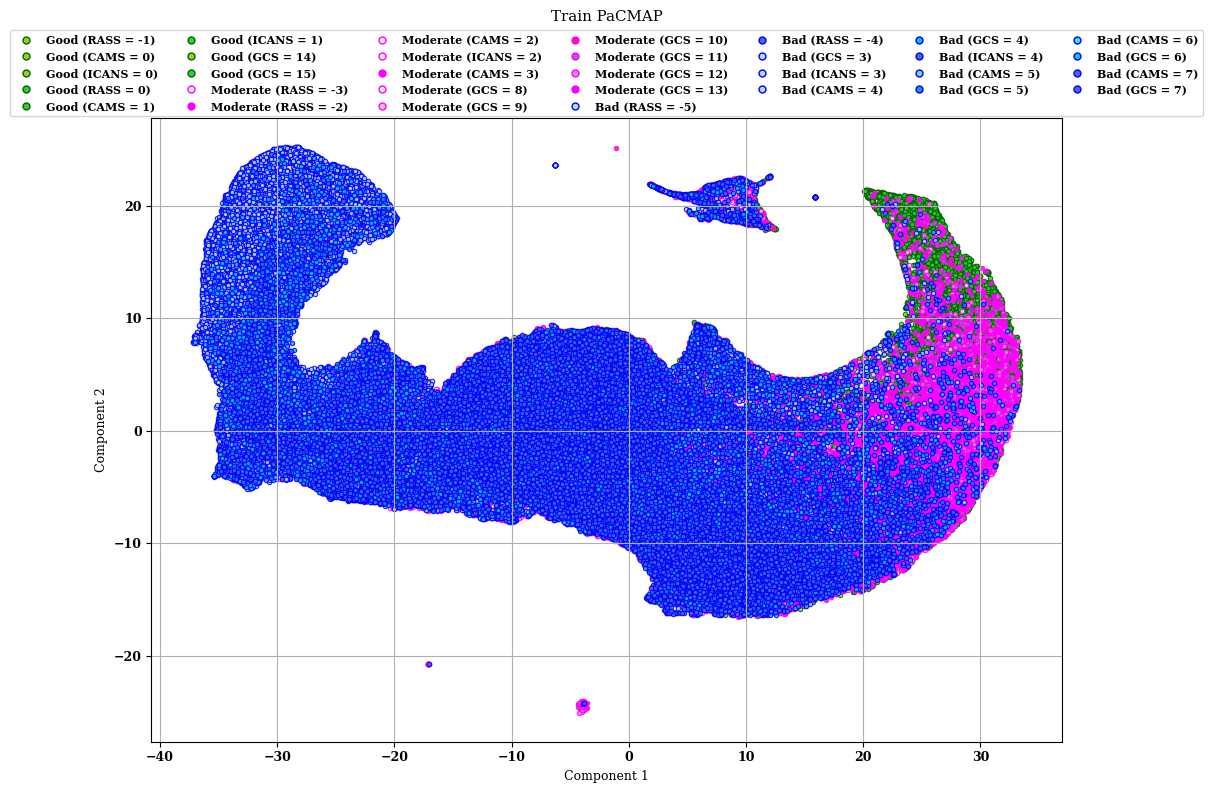

In [19]:
plot_pacmap_granular(train_pacmap, 
                     Ygrouped_train_trch,
                     Yraw_train_trch,
                     train_dataset_names,
                     title="Train PaCMAP")

#### **Validation PacMAPs**

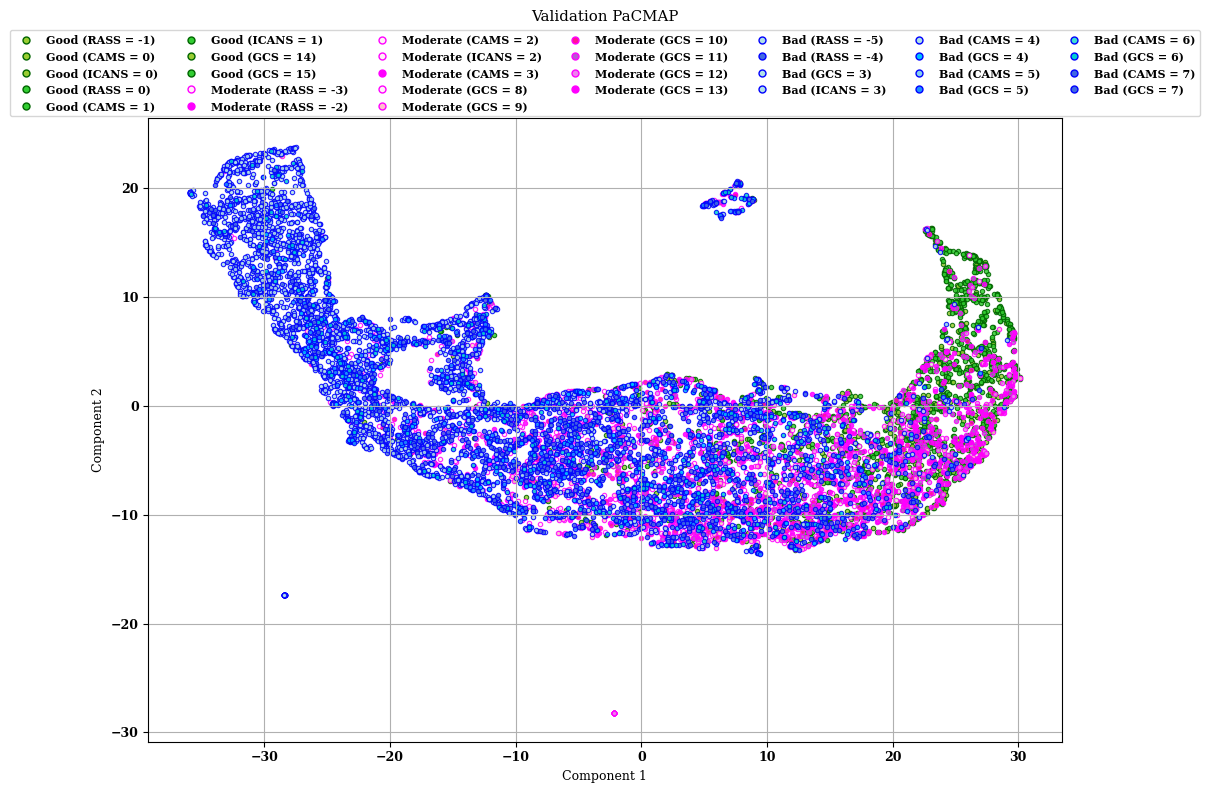

In [20]:
plot_pacmap_granular(val_pacmap, 
                     Ygrouped_val_trch,
                     Yraw_val_trch,
                     val_dataset_names,
                     title="Validation PaCMAP")

#### **Test static PacMAPs**

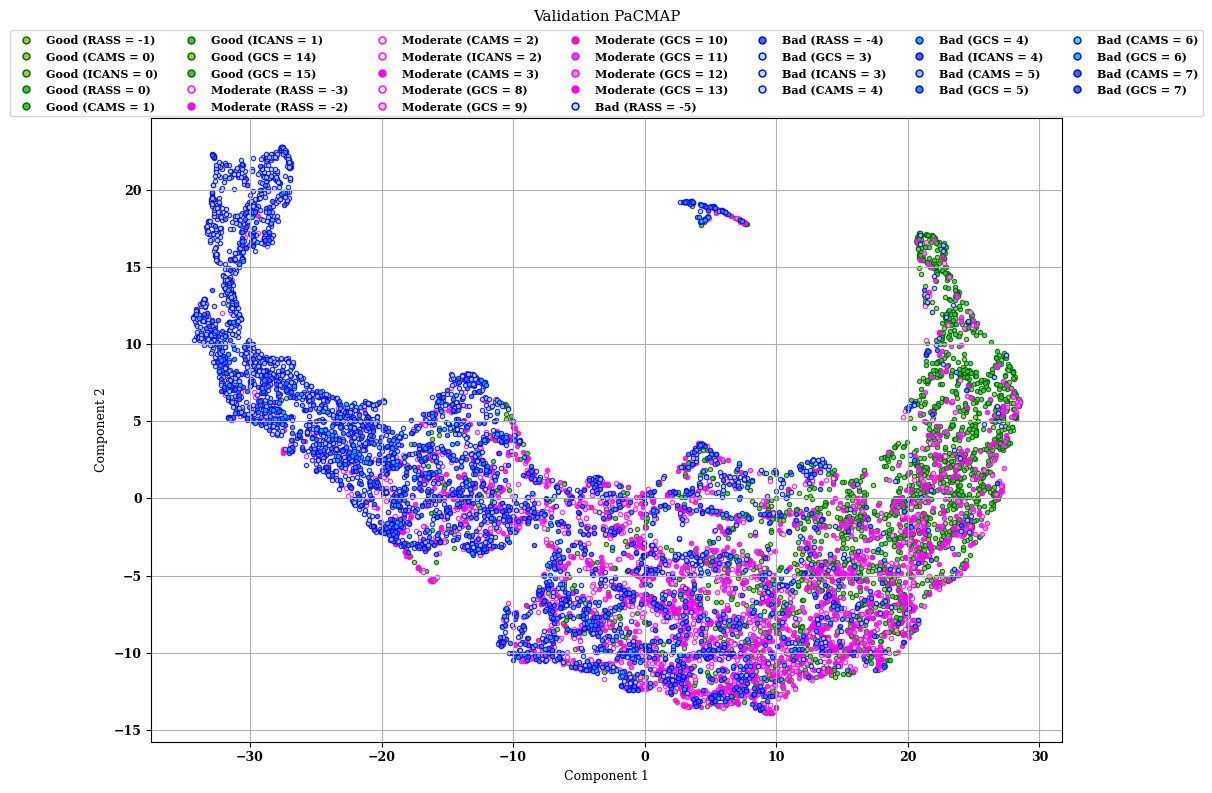

In [21]:
plot_pacmap_granular(tst_pacmap, 
                     Ygrouped_tst_trch,
                     Yraw_tst_trch,
                     tst_dataset_names,
                     title="Validation PaCMAP")